# Dependencies

In [ ]:
import json
import pandas as pd
from collections import OrderedDict
import numpy as np
import itertools
import math
import re
import matplotlib.pyplot as plt
import seaborn as sns
from bioservices import KEGG
from sklearn.preprocessing import StandardScaler
from scipy.stats import hypergeom

Creating directory /root/.config/bioservices 


In [3]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
with open("../results/GSE10072_results.json", "r") as f:
    results = json.load(f)

In [ ]:
with open("../results_baseline/GSE10072_results_baseline.json", "r") as f:
    baseline_results = json.load(f)

# Algorithm performance

### Accuracy (mean ± std) overview

In [ ]:
summary = results["summary"]
baseline_summary = baseline_results["summary"]

In [ ]:
def format_mean_std(mean, std, decimals=4):
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"

In [ ]:
svm_baseline_str = format_mean_std(
    baseline_summary["svm_all_features"]["accuracy_mean"],
    baseline_summary["svm_all_features"]["accuracy_std"]
)

max_apriori_str = format_mean_std(
    baseline_summary["max_apriori"]["accuracy_mean"],
    baseline_summary["max_apriori"]["accuracy_std"]
)

In [ ]:
rows = []
for algo, metrics in summary.items():
    fs_acc_str = format_mean_std(
        metrics["accuracy_mean"],
        metrics["accuracy_std"]
    )

    rows.append({
        "algorithm": algo,
        "feature selection accuracy (mean ± std)": fs_acc_str,
        "baseline accuracy (mean ± std)": svm_baseline_str,
        "max a priori accuracy (mean ± std)": max_apriori_str
    })

df_results = pd.DataFrame(rows)

In [ ]:
df_results

,algorithm,feature selection accuracy (mean ± std),baseline accuracy (mean ± std),max a priori accuracy (mean ± std)
0,rand_sel,0.9682 ± 0.0183,0.9925 ± 0.0037,0.5318 ± 0.0308
1,pear_corr,0.9972 ± 0.0043,0.9925 ± 0.0037,0.5318 ± 0.0308
2,svm_rfe,0.9841 ± 0.0060,0.9925 ± 0.0037,0.5318 ± 0.0308
3,ga,0.9495 ± 0.0237,0.9925 ± 0.0037,0.5318 ± 0.0308
4,pbil,0.9617 ± 0.0194,0.9925 ± 0.0037,0.5318 ± 0.0308
5,sa,0.9850 ± 0.0086,0.9925 ± 0.0037,0.5318 ± 0.0308
6,bwo,0.9766 ± 0.0163,0.9925 ± 0.0037,0.5318 ± 0.0308


### Histogram of feature selection frequencies


In [5]:
total_freq = results.get("total_feature_freq", {})
algorithms = list(total_freq.keys())

In [6]:
# compute normalized frequencies per algorithm
MAX_FOLDS = 100

algo_norm_freqs = {}

for algo in algorithms:
    freq_dict = total_freq.get(algo, {})

    if len(freq_dict) == 0:
        algo_norm_freqs[algo] = np.array([], dtype=float)
        continue

    # convert to normalized frequencies: freq / 100
    freqs = np.array(list(freq_dict.values()), dtype=float)
    freqs_norm = freqs / MAX_FOLDS

    algo_norm_freqs[algo] = freqs_norm

Text(0.5, 1.02, 'Histogram of Normalized Feature Frequencies (per algorithm)')

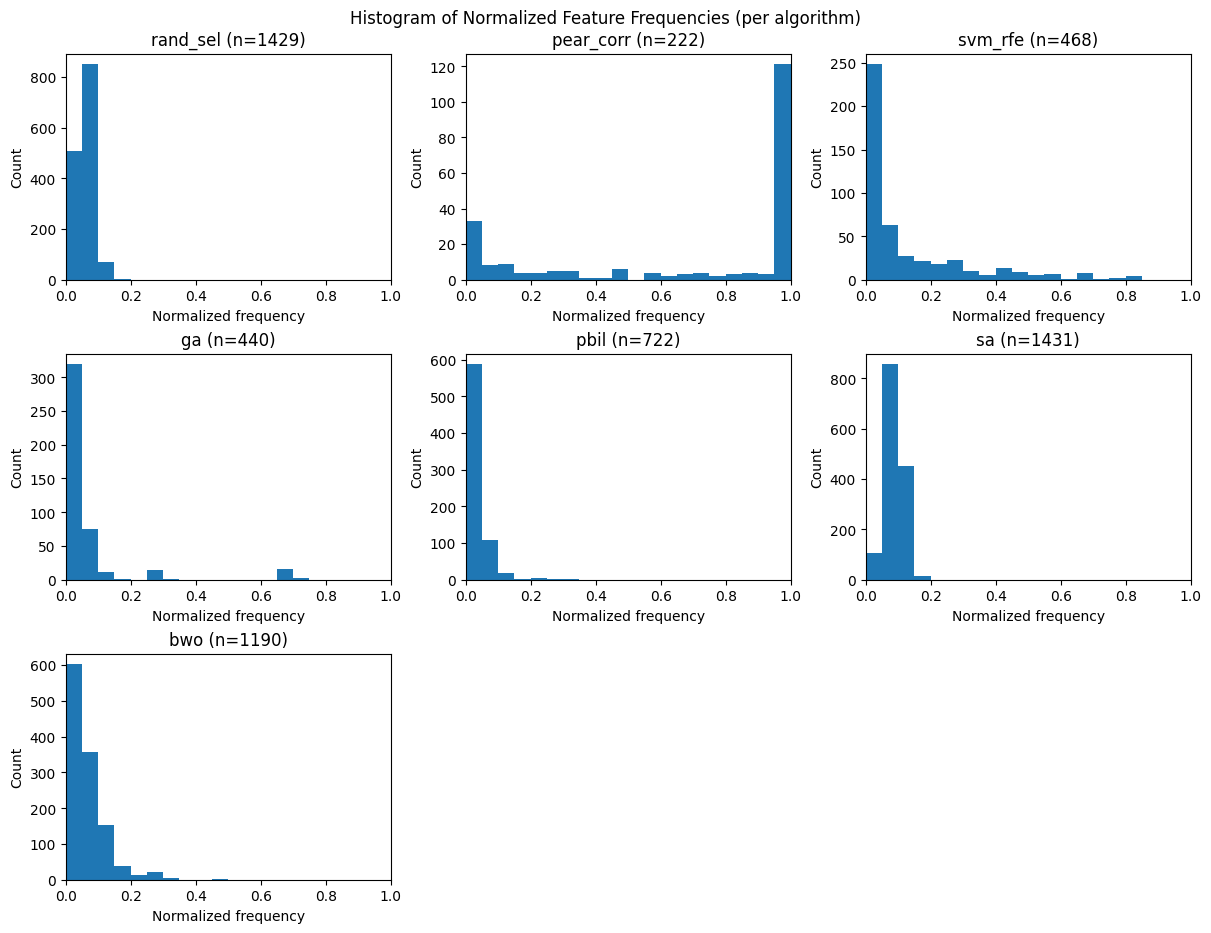

In [ ]:
# Plot histograms
n = len(algorithms)

# subplot grid
BINS = 20
cols = min(3, n)
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3*rows), constrained_layout=True)
axes = np.array(axes).reshape(-1)

for ax_idx, algo in enumerate(algorithms):
    ax = axes[ax_idx]
    vals = algo_norm_freqs[algo]
    if vals.size == 0:
        ax.text(0.5, 0.5, "no data", ha="center", va="center")
        ax.set_title(algo)
        ax.set_xlim(0, 1)
        ax.set_xlabel("Normalized frequency")
        ax.set_ylabel("Count")
        continue

    # Use 0..1 bins for clean interpretation
    bins = np.linspace(0.0, 1.0, BINS + 1)
    ax.hist(vals, bins=bins)
    ax.set_title(f"{algo} (n={vals.size})")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Normalized frequency")
    ax.set_ylabel("Count")

# Turn off any remaining empty axes
for idx in range(len(algorithms), len(axes)):
    axes[idx].axis("off")

fig.suptitle("Histogram of Normalized Feature Frequencies (per algorithm)", y=1.02)

### Stability of top-k

In [ ]:
# Load feature names
df = pd.read_csv("../dataset/GSE10072/reduced.csv")
feature_cols = df.drop(columns=["label"]).columns.tolist()

topk_dict = {}
K = 50

for algo in algorithms:
    freq_dict = total_freq.get(algo, {})
    if not freq_dict:
        topk_dict[algo] = {
            "total_selected_features": 0,
            "top_k_count": 0,
            "top_k_norm_frequencies": [],
            "top_k_feature_names": [],
            "top_k_indices": [],
            "stability_range_pct": ""
        }
        continue

    # Convert keys -> ints and pair with raw freq
    items = [(int(idx), int(v)) for idx, v in freq_dict.items()]

    total_selected = len(items)

    # Determine top-k (if fewer than K, then take all)
    top_k_items = items[:K] if total_selected >= K else items

    top_k_indices = [idx for idx, freq in top_k_items]
    top_k_raw_freqs = [freq for idx, freq in top_k_items]
    top_k_norm_freqs = [float(freq) / float(MAX_FOLDS) for freq in top_k_raw_freqs]

    # Compute stability range (min-max) as percentages
    if top_k_norm_freqs:
        min_pct = int(round(min(top_k_norm_freqs) * 100))
        max_pct = int(round(max(top_k_norm_freqs) * 100))
        stability_range_str = f"{min_pct:.1f}-{max_pct:.1f}%"
    else:
        stability_range_str = ""

    # Map indices to feature names
    top_k_feature_names = [feature_cols[idx] for idx in top_k_indices]

    # Build dict
    topk_dict[algo] = {
        "total_selected_features": total_selected,
        "top_k_count": len(top_k_indices),
        "top_k_norm_frequencies": top_k_norm_freqs,
        "top_k_feature_names": top_k_feature_names,
        "top_k_indices": top_k_indices,
        "stability_range_pct": stability_range_str
    }

In [ ]:
rows = []
for algo in algorithms:
    entry = topk_dict.get(algo, {})
    rows.append({
        "algorithm": algo,
        "total_selected_features": entry.get("total_selected_features", 0),
        "top_k_count": entry.get("top_k_count", 0),
        "stability_range_pct": entry.get("stability_range_pct", "")
    })

topk_summary_df = pd.DataFrame(rows)

In [ ]:
topk_summary_df

,algorithm,total_selected_features,top_k_count,stability_range_pct
0,rand_sel,1429,50,10.0-16.0%
1,pear_corr,222,50,100.0-100.0%
2,svm_rfe,468,50,40.0-84.0%
3,ga,440,50,8.0-72.0%
4,pbil,722,50,7.0-33.0%
5,sa,1431,50,14.0-18.0%
6,bwo,1190,50,18.0-45.0%


### Heatmap of top-k

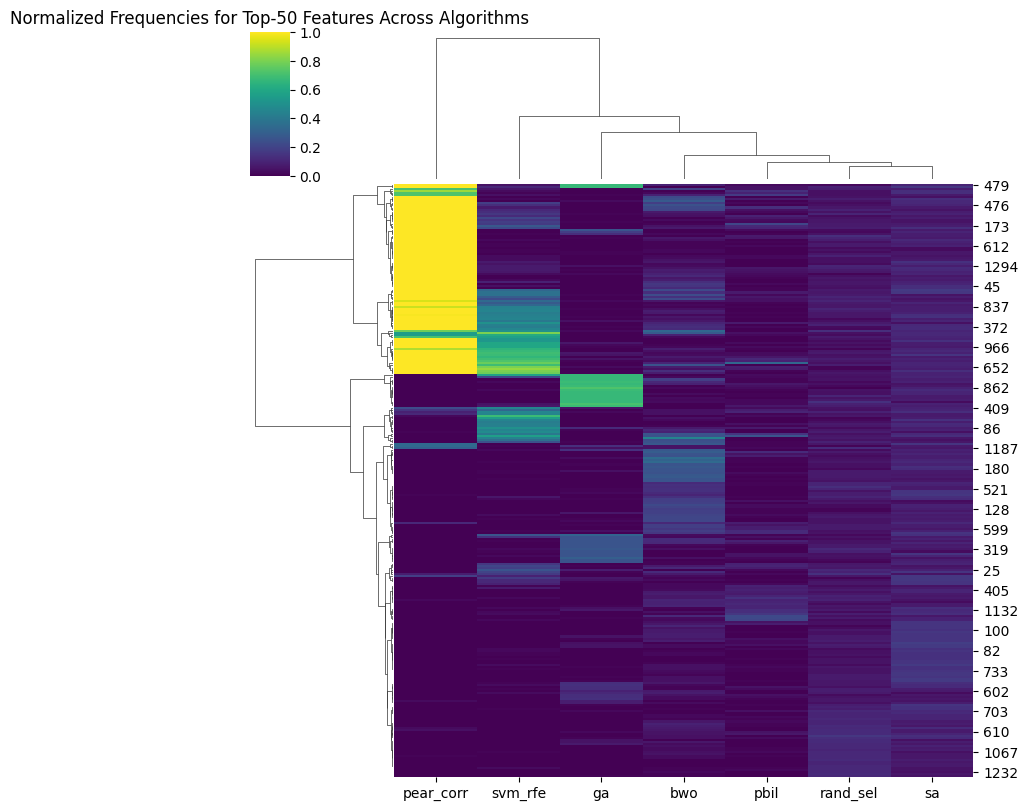

In [ ]:
all_top_feats = set()
for algo in topk_dict:
    all_top_feats.update(topk_dict[algo]["top_k_indices"])

all_top_feats = sorted(all_top_feats)

heatmap_matrix = pd.DataFrame(index=all_top_feats, columns=algorithms, dtype=float)

for algo in algorithms:
    freq_dict = total_freq.get(algo, {})
    for feat in all_top_feats:
        raw = freq_dict.get(str(feat), freq_dict.get(int(feat), 0))
        heatmap_matrix.loc[feat, algo] = raw / MAX_FOLDS

sns.clustermap(
    heatmap_matrix,
    cmap="viridis",
    figsize=(8, 8),
    metric="euclidean",
    method="ward"
)
plt.title(f"Normalized Frequencies for Top-{K} Features Across Algorithms")
plt.show()

In [ ]:
print(len(all_top_feats))
print(heatmap_matrix.shape)

293
(293, 7)


### Common features among top-k

In [ ]:
# inclusive intersection counts
topk_sets = {}
for algo, info in topk_dict.items():
    topk_sets[algo] = set(info["top_k_feature_names"])

records = []

for r in range(2, len(algorithms)+1):
    for combo in itertools.combinations(algorithms, r):
        # intersect features
        intersect_feats = set.intersection(*(topk_sets[algo] for algo in combo))
        if intersect_feats:
            records.append({
                "algorithms": ", ".join(combo),
                "count": len(intersect_feats),
                "features": ", ".join(sorted(intersect_feats))
            })

overlap_df = pd.DataFrame(records)

# show only rows with non-empty overlaps
overlap_df = overlap_df[overlap_df["count"] > 0].reset_index(drop=True)

In [ ]:
overlap_df.head()

,algorithms,count,features
0,"rand_sel, pear_corr",2,"IL7R, THBS2"
1,"rand_sel, svm_rfe",2,"CSF3R, NTRK3"
2,"rand_sel, ga",3,"IRF7, MSN, PCK1"
3,"rand_sel, pbil",1,IL7R
4,"rand_sel, bwo",1,NTRK3


### Parallel coordinates plot

In [ ]:
reduced_df = pd.read_csv("../dataset/GSE10072/reduced.csv")
feature_df = reduced_df.drop(columns=["label"])
df_labels = reduced_df["label"].values

# Standardize gene expression values
scaler = StandardScaler()
scaled_features = pd.DataFrame(
    scaler.fit_transform(feature_df),
    columns=feature_df.columns,
    index=feature_df.index
)

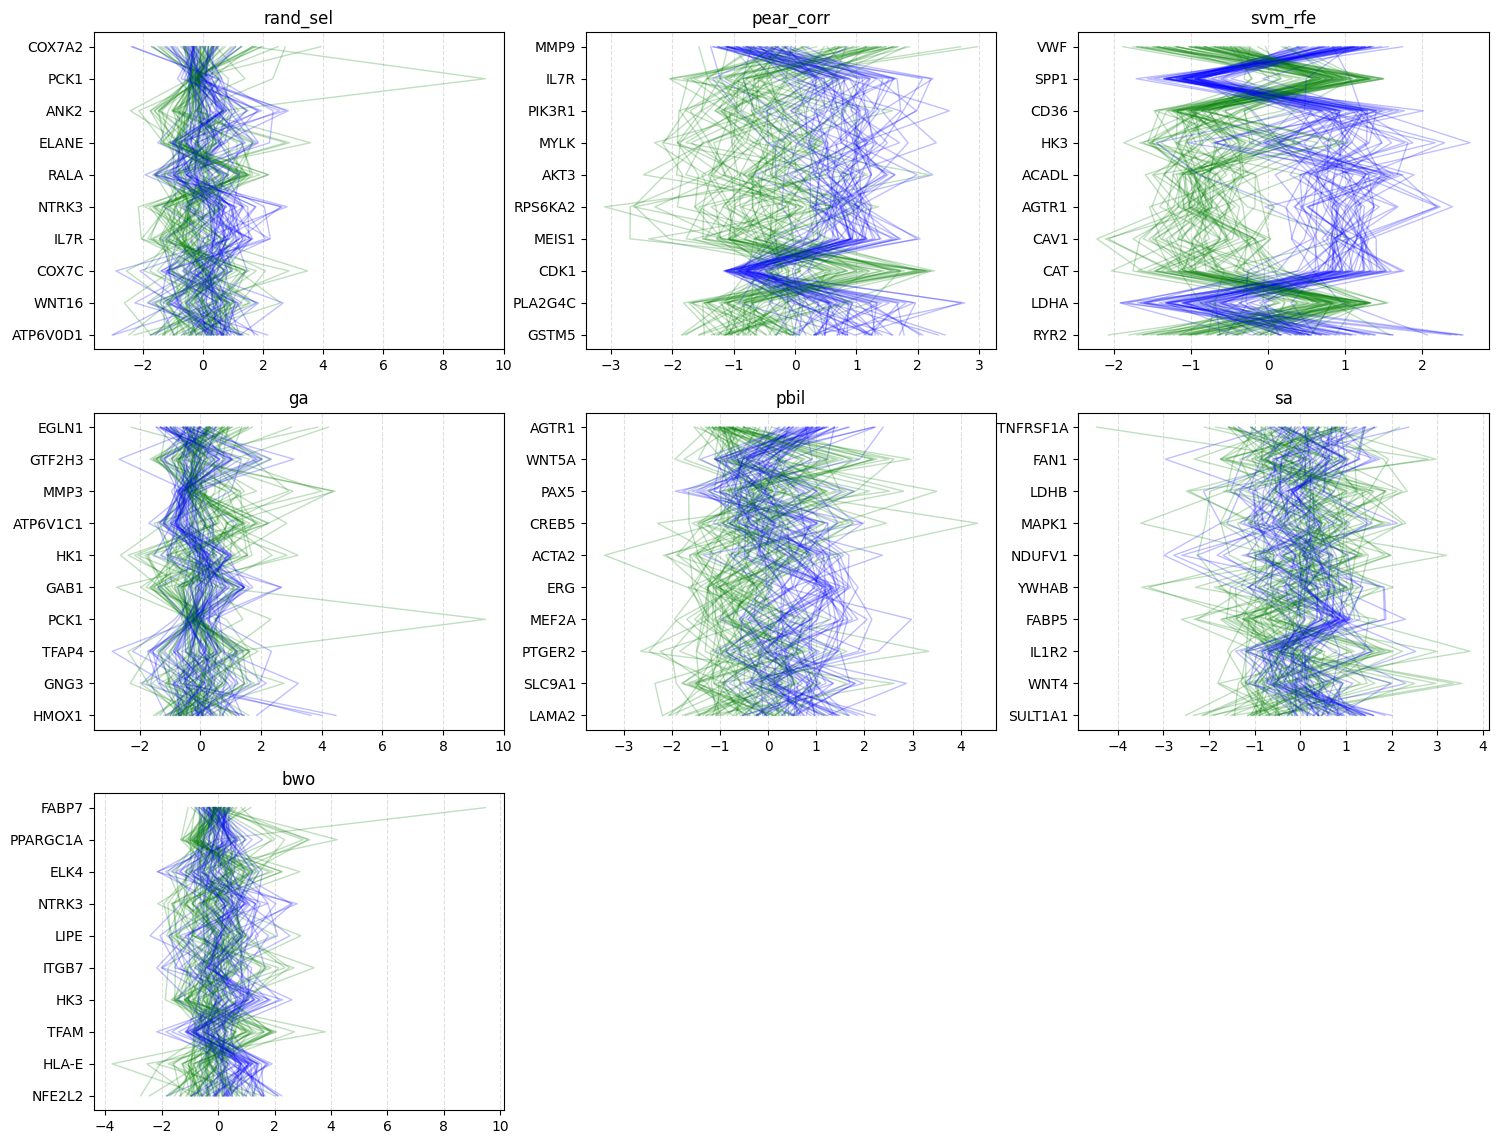

In [ ]:
TOP_N = 10
algorithms = list(topk_dict.keys())

n_rows, n_cols = 3, 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 14))
axes = axes.flatten()

class_colors = {0: "blue", 1: "green"}

for ax_idx, algo in enumerate(algorithms):
    ax = axes[ax_idx]
    info = topk_dict[algo]

    feature_names = info["top_k_feature_names"][:TOP_N]

    data = scaled_features[feature_names]
    y_positions = np.arange(TOP_N)

    # Plot each patient/sample
    for i in range(len(data)):
        ax.plot(
            data.iloc[i].values,
            y_positions,
            color=class_colors[df_labels[i]],
            alpha=0.25,
            linewidth=1.0
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(feature_names)
    ax.invert_yaxis()

    # ax.set_xlabel("Standardized Expression")
    ax.set_title(algo)
    ax.grid(axis="x", linestyle="--", alpha=0.4)

# Turn off unused subplots
for j in range(len(algorithms), n_rows * n_cols):
    axes[j].axis("off")

# Biological relevance

### KEGG overlap analysis (p-value)

In [9]:
topk_genes_per_algo = OrderedDict()

for algo, info in topk_dict.items():
    feature_names = info["top_k_feature_names"]
    topk_genes_per_algo[algo] = set(
        gene.upper().strip() for gene in feature_names
    )

# total genes in dataset
U = len(feature_cols)

# KEGG pathways for lung
kegg_pathway_list = {
    'hsa05223': 'Non-small cell lung cancer',
    'hsa05222': 'Small cell lung cancer',
    'hsa04010': 'MAPK signaling pathway',
    'hsa04151': 'PI3K-Akt signaling pathway',
    'hsa04115': 'p53 signaling pathway'
}

In [10]:
def fetch_kegg_aml_symbols(pathway):
    k = KEGG()
    entry = k.get(pathway)
    parsed = k.parse(entry)
    symbols = set()
    if 'GENE' in parsed:
        for entrez, desc in parsed['GENE'].items():
            m = re.match(r"^([A-Za-z0-9\-\._]+)", desc)
            if m:
                symbols.add(m.group(1).upper().strip())
    return symbols

In [11]:
rows = []

for pathway_code, pathway_name in kegg_pathway_list.items():

    # KEGG pathway genes
    kegg_genes = fetch_kegg_aml_symbols(pathway_code)
    K = len(kegg_genes)

    for algo, algo_genes in topk_genes_per_algo.items():

        k = topk_dict[algo]["top_k_count"]

        intersect = algo_genes.intersection(kegg_genes)
        overlap = len(intersect)

        rows.append({
            "pathway_code": pathway_code,
            "pathway_name": pathway_name,
            "algorithm": algo,
            "pathway_size": K,
            "top_k": k,
            "overlap": overlap,
            "intersected_genes": ", ".join(sorted(intersect))
        })

results_df = pd.DataFrame(rows)

Creating directory /root/.cache/bioservices 
Welcome to Bioservices
It looks like you do not have a configuration file.
We are creating one with default values in /root/.config/bioservices/bioservices.cfg .
Done


In [ ]:
# Add p-value column
results_df["p_value"] = 1.0

U = len(feature_cols)

for i, row in results_df.iterrows():
    K = row["pathway_size"]   
    k = row["top_k"]          
    overlap = row["overlap"]  

    # Hypergeometric one-sided p-value 
    p_val = hypergeom.sf(overlap - 1, M=U, n=K, N=k)

    results_df.at[i, "p_value"] = p_val

results_df["neg_log10_p"] = -np.log10(results_df["p_value"].replace(0, 1e-300)) 

In [13]:
results_df

,pathway_code,pathway_name,algorithm,pathway_size,top_k,overlap,intersected_genes,p_value,neg_log10_p
0,hsa05223,Non-small cell lung cancer,rand_sel,73,50,1,DDB2,0.930412,0.031325
1,hsa05223,Non-small cell lung cancer,pear_corr,73,50,2,"AKT3, PIK3R1",0.736373,0.132902
2,hsa05223,Non-small cell lung cancer,svm_rfe,73,50,1,ERBB2,0.930412,0.031325
3,hsa05223,Non-small cell lung cancer,ga,73,50,1,PIK3R3,0.930412,0.031325
4,hsa05223,Non-small cell lung cancer,pbil,73,50,1,STAT5B,0.930412,0.031325
5,hsa05223,Non-small cell lung cancer,sa,73,50,1,MAPK1,0.930412,0.031325
6,hsa05223,Non-small cell lung cancer,bwo,73,50,1,RXRA,0.930412,0.031325
7,hsa05222,Small cell lung cancer,rand_sel,93,50,3,"CCNE2, CKS2, DDB2",0.643383,0.191530
8,hsa05222,Small cell lung cancer,pear_corr,93,50,3,"AKT3, COL4A3, PIK3R1",0.643383,0.191530
9,hsa05222,Small cell lung cancer,svm_rfe,93,50,1,COL4A5,0.967315,0.014432


### Heatmap

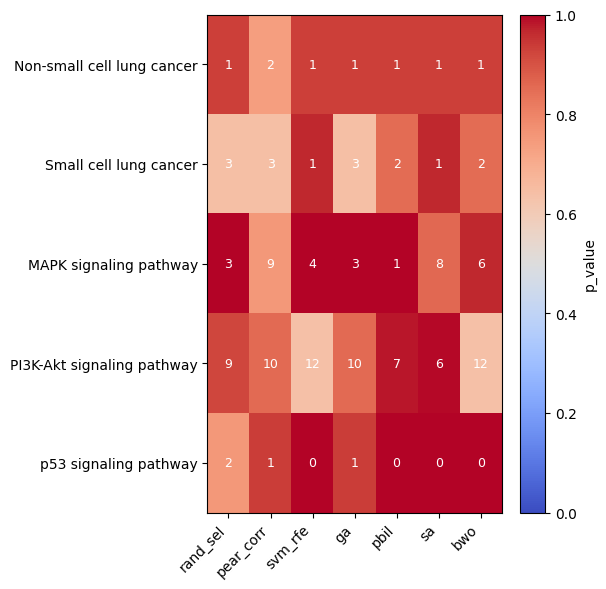

In [ ]:
heatmap_df = results_df.copy()
algo_order = list(topk_genes_per_algo.keys())
pathway_order = list(kegg_pathway_list.values())

heatmap_df["algorithm"] = pd.Categorical(
    heatmap_df["algorithm"],
    categories=algo_order,
    ordered=True
)

heatmap_df["pathway_name"] = pd.Categorical(
    heatmap_df["pathway_name"],
    categories=pathway_order,
    ordered=True
)

pivot_nes = heatmap_df.pivot_table(
    index="pathway_name",
    columns="algorithm",
    values="p_value",
    aggfunc="mean"
)

pivot_overlap = heatmap_df.pivot_table(
    index="pathway_name",
    columns="algorithm",
    values="overlap",
    aggfunc="mean"
)

plt.figure(figsize=(6, 6))
plt.imshow(pivot_nes, aspect='auto', cmap="coolwarm", vmin=0, vmax=1)
plt.colorbar(label="p_value")

plt.xticks(
    ticks=range(len(pivot_nes.columns)),
    labels=pivot_nes.columns,
    rotation=45, ha='right'
)
plt.yticks(
    ticks=range(len(pivot_nes.index)),
    labels=pivot_nes.index
)

# Add overlap annotations
for i in range(pivot_nes.shape[0]):
    for j in range(pivot_nes.shape[1]):
        val = int(pivot_overlap.iloc[i, j])
        plt.text(j, i, str(val), ha='center', va='center', color='white', fontsize=9)

plt.tight_layout()
plt.show()